# Embedding fine-tuning: data, negatives, training, evaluation and export

English | [简体中文](01_finetune.zh-CN.ipynb)

## Goal

Run a model/hardware-configurable embedding workflow. The default offline random
tiny BERT and synthetic retrieval data exercise the actual training implementation.
**Example metrics do not represent domain quality.**

Artifacts include prepared training negatives, validation selection history,
baseline/selected retrieval metrics and a native SentenceTransformer export.

## Setup

From the repository root: `python -m pip install -e '.[embedding,notebooks]'`.
On Colab, first place the repository at `/content/advai-notebooks`, then use
`%pip install -e '/content/advai-notebooks[embedding,notebooks]'` and set `ROOT` below.

In [1]:
from pathlib import Path
import sys
import importlib.metadata

# Colab: set ROOT = Path("/content/advai-notebooks") after placing the repo there.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "pyproject.toml").exists()), None)
if ROOT is None:
    raise RuntimeError("Set ROOT to the repository directory before continuing")
sys.path.insert(0, str(ROOT / "src"))
for name in ["torch", "transformers", "sentence-transformers"]:
    print(name, importlib.metadata.version(name))
print("Repository:", ROOT)
from huggingface_hub.utils import disable_progress_bars
from transformers.utils.logging import disable_progress_bar
disable_progress_bars()
disable_progress_bar()


torch 2.14.0
transformers 5.18.0
sentence-transformers 5.7.0
Repository: /Users/xuyi/Documents/workspace/advai-notebooks


## Step 1 — Configure and validate data

YAML controls base/revision, query/document prefixes, pooling, context length, loss,
batches, accumulation, device and precision. Every notebook execution creates a
fresh experiment directory rather than overwriting prior artifacts.

In [2]:
import tempfile
from advai_notebooks.embedding.config import load_config
from advai_notebooks.common.retrieval_data import load_data

CONFIG = ROOT / "configs/embedding/smoke.yaml"  # Domain data: configs/embedding/bge.yaml
cfg = load_config(CONFIG, root=ROOT)
parent = ROOT / "outputs/embedding"
parent.mkdir(parents=True, exist_ok=True)
RUN_DIR = Path(tempfile.mkdtemp(prefix="notebook-", dir=parent)) / "run"
cfg.output_dir = str(RUN_DIR)
data = load_data(cfg)
print(data.summary())
print("Model:", cfg.model)
print("Runtime:", cfg.runtime)
print("Run:", RUN_DIR)

{'documents': 12, 'queries': 18, 'judgments': 216, 'queries_by_split': {'train': 12, 'validation': 3, 'test': 3}, 'fingerprint': 'f96589e88e79ce684f3c8733ae1a3c98a8f028459f6e82e3477efeb2867b2a19', 'document_group_isolation': True}
Model: ModelConfig(id='tiny', revision=None, max_len=64, query_prefix='', document_prefix='', pooling='mean')
Runtime: RuntimeConfig(device='cpu', precision='fp32', num_threads=2)
Run: /Users/xuyi/Documents/workspace/advai-notebooks/outputs/embedding/notebook-6c8hynii/run


## Step 2 — Inspect independently prepared training samples

Training reads `data.training_samples`; it does not mine negatives. Run
`python -m advai_notebooks.data_preparation prepare --config configs/data_preparation/smoke.yaml`
separately, then set the generated `embedding_samples.json` path in the training config.

Fixtures already contain judged positives/negatives. Query and document IDs are
validated against qrels. Held-out queries and known positives cannot become
training negatives. Sampling also avoids known in-batch false negatives.

In [3]:
from advai_notebooks.embedding.data import load_training_samples
from advai_notebooks.embedding.sampling import embedding_batches

rows, samples_fingerprint = load_training_samples(cfg, data)
batches = embedding_batches(rows, data, cfg.training.batch_size, cfg.training.seed)
print("Prepared rows:", len(rows), "Sample fingerprint:", samples_fingerprint)
print("First batch sizes:", [len(b) for b in batches[:10]])
for row in rows[:2]:
    print(row)
    print("Query:", data.queries[row["query_id"]]["text"])
    print("Positive:", data.corpus[row["positive_id"]]["text"])
    print("Negatives:", [data.corpus[d]["text"] for d in row["negative_ids"]])

Prepared rows: 24 Sample fingerprint: cebc151f0e9c04eae8c92a1d79a8c3ae6771b1a81fb7484e7a13a34555ee9173
First batch sizes: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
{'query_id': 'crash-0', 'positive_id': 'crash-guide', 'negative_ids': ['invoice-guide', 'invoice-help']}
Query: how app crash technical bug fix
Positive: app crash technical bug fix
Negatives: ['subscription billing invoice payment', 'help subscription billing invoice payment contact service']
{'query_id': 'crash-0', 'positive_id': 'crash-help', 'negative_ids': ['invoice-guide', 'invoice-help']}
Query: how app crash technical bug fix
Positive: help app crash technical bug fix contact service
Negatives: ['subscription billing invoice payment', 'help subscription billing invoice payment contact service']


## Step 3 — Train, select on validation and report test results

MNRL distinguishes paired positives from in-batch/explicit hard negatives.
`cached_mnrl` reduces activation memory. Gradient accumulation does not enlarge
the negative pool of an individual loss calculation.

Selection includes epoch zero and never uses test. If training does not improve
validation, the baseline is exported and `best_epoch=0` is recorded explicitly.

In [4]:
from advai_notebooks.embedding.pipeline import run
report = run(cfg)
print("Selected epoch:", report["training"]["best_epoch"])
print("Export:", report["export"])

embedding: epoch 1, loss=0.0754, validation mrr@3=1.0000


embedding: epoch 2, loss=0.0000, validation mrr@3=1.0000


Selected epoch: 0
Export: /Users/xuyi/Documents/workspace/advai-notebooks/outputs/embedding/notebook-6c8hynii/run/export


## Checks — Training history and retrieval metrics

Recall uses all known positives as its denominator; MRR measures the first relevant
result; nDCG uses graded relevance. Unjudged documents receive zero offline gain.
Search covers the complete corpus without inserting missing positives into candidates.

Checkpoint,recall@3,mrr@3,ndcg@3
Before training,1.0000,1.0000,1.0000
Selected export,1.0000,1.0000,1.0000


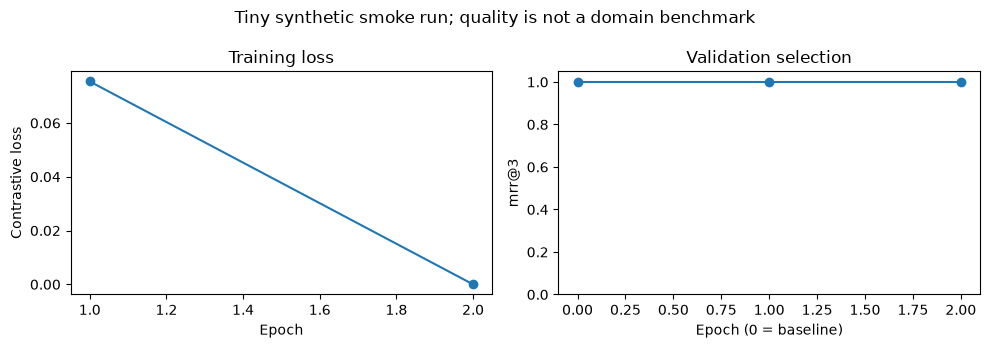

In [5]:
import math
from IPython.display import display, HTML
import matplotlib.pyplot as plt

history = report["training"]["history"]
assert all(math.isfinite(h["train_loss"]) for h in history[1:])
K = 3 if 3 in cfg.evaluation.cutoffs else (10 if 10 in cfg.evaluation.cutoffs else cfg.evaluation.cutoffs[0])
keys = [f"{metric}@{K}" for metric in ["recall", "mrr", "ndcg"]]
rows = [(name, report[field]["metrics"]) for name, field in
        [("Before training", "baseline_test"), ("Selected export", "finetuned_test")]]
html = "<table><tr><th>Checkpoint</th>" + "".join(f"<th>{k}</th>" for k in keys) + "</tr>"
for name, metrics in rows:
    html += f"<tr><td>{name}</td>" + "".join(f"<td>{metrics[k]:.4f}</td>" for k in keys) + "</tr>"
display(HTML(html + "</table>"))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot([h["epoch"] for h in history[1:]], [h["train_loss"] for h in history[1:]], marker="o")
axes[0].set(xlabel="Epoch", ylabel="Contrastive loss", title="Training loss")
selection_metric = cfg.evaluation.selection_metric
axes[1].plot([h["epoch"] for h in history], [h["validation"][selection_metric] for h in history], marker="o")
axes[1].set(xlabel="Epoch (0 = baseline)", ylabel=selection_metric, title="Validation selection")
axes[1].set_ylim(0, 1.05)
fig.suptitle("Tiny synthetic smoke run; quality is not a domain benchmark")
fig.tight_layout()
fig.savefig(RUN_DIR / "training.png", dpi=130)
plt.show()

## Step 4 — Reload and verify native SDK agreement

Query/document prefixes are saved as native prompts. Use SDK `encode_query` /
`encode_document`; specify `role` explicitly with the wrapper's `encode`.
Vectors are normalized, so dot products equal cosine similarities.

In [6]:
from advai_notebooks.embedding.model import EmbeddingModel
import numpy as np
from sentence_transformers import SentenceTransformer

exported = EmbeddingModel.load(report["export"], device="cpu")
sdk = SentenceTransformer(report["export"], device="cpu")
texts = ["reset password", "card charged twice"]
vectors = exported.encode(texts, role="query").numpy()
np.testing.assert_allclose(vectors, sdk.encode_query(texts, show_progress_bar=False), atol=1e-6)
np.testing.assert_allclose(np.linalg.norm(vectors, axis=1), 1, atol=1e-6)
print("Reload and native SDK agreement passed. Shape:", vectors.shape)
print("Artifacts:", sorted(p.name for p in RUN_DIR.iterdir()))

Reload and native SDK agreement passed. Shape: (2, 32)
Artifacts: ['baseline', 'baseline_test.json', 'baseline_test_rankings.json', 'best', 'config.json', 'data_summary.json', 'environment.json', 'export', 'history.json', 'latest', 'report.json', 'test_rankings.json', 'training.png', 'training_samples.json']


## Next Steps

- Prepare domain corpus/queries/qrels using `data/sample/retrieval/README.md`, with source-disjoint groups and explicitly judged negatives.
- Adapt `configs/embedding/bge.yaml` or a compatible single-vector encoder, setting required prefixes/pooling and pinning revision.
- Adjust batch size, cached mini-batches, `max_len` and gradient checkpointing for memory. CUDA can use fp16/bf16; CPU/MPS use fp32.
- Train Ranker independently; optional composition is in `notebooks/workflows/01_retrieval_comparison.ipynb`.

Single-device full training supports completed-epoch optimizer/scaler/RNG recovery
with the original config and `--resume <output_dir>/latest`. Inference exports are
not training-state checkpoints. Changed config/data/source requires a new experiment.
Real-model quality and CUDA/MPS behavior need separate target-hardware checks.

## Optional: publish to Hugging Face

Set `REPO_ID` to a repository you control (`namespace/model`). The default
`UPLOAD_TO_HUB = False` validates the inference package offline and saves a manifest.
Only `True` enables upload. Authenticate with `hf auth login` or `HF_TOKEN` before
an actual upload. Repositories default to private; choose licenses explicitly.
See the [publication guide](../../docs/publishing.md).

In [7]:
from advai_notebooks.embedding.publish import publish
from advai_notebooks.common.artifacts import write_json

REPO_ID = "your-org/your-embedding"
UPLOAD_TO_HUB = False
PUBLIC = False
LICENSE = None
publication = publish(
    report["export"], REPO_ID,
    private=not PUBLIC, license=LICENSE, dry_run=not UPLOAD_TO_HUB,
)
publication_path = RUN_DIR / "publication.json"
write_json(publication_path, publication)
print("Publication:", publication["status"])
print("Files:", [row["path"] for row in publication["files"]])
print("Result / preview:", publication_path)
if publication.get("commit"):
    print("Pin this revision:", publication["commit"])

Publication: dry_run
Files: ['1_Pooling/config.json', 'README.md', 'advai_metadata.json', 'config.json', 'config_sentence_transformers.json', 'model.safetensors', 'modules.json', 'sentence_bert_config.json', 'tokenizer.json', 'tokenizer_config.json']
Result / preview: /Users/xuyi/Documents/workspace/advai-notebooks/outputs/embedding/notebook-6c8hynii/run/publication.json
